# Analyse Big Data des accidents de la route en Australie-Méridionale avec PySpark

**Objectif** : reproduire puis compléter les analyses du dépôt
[RakeshNain / Big-data-Analysis-of-Road-Crash-Data-using-PySpark](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial).

**Données** : accidents de la route 2012-2019 en Australie-Méridionale (source : DPTI, data.sa.gov.au), deux jeux de fichiers CSV :
- **Crash** : une ligne par accident (lieu, date, conditions, gravité, alcool/drogues…) — 127 672 lignes ;
- **Units** : une ligne par « unité » impliquée (véhicule, piéton, cycliste, obstacle fixe…) — 272 591 lignes.

Les deux sont reliés par la clé `REPORT_ID`.

| Partie | Contenu |
|---|---|
| **A. Reproduction** | Analyses du dépôt d'origine avec les trois API de Spark : RDD, DataFrame, Spark SQL. Les erreurs repérées dans le code d'origine sont signalées par ⚠️ et corrigées. |
| **B. Benchmark** | Comparaison RDD / DataFrame / SQL : temps, plans d'exécution, nombre de cœurs, partitions de shuffle |
| **C. Nouvelles analyses** | Quand, où et dans quelles conditions les accidents sont-ils les plus graves ? |

## 0. Mise en place

### 0.1 Les données
Les 16 fichiers CSV (environ 80 Mo) : `crash_data/` (un fichier par année, 2012-2019) et `units_data/`.

In [3]:
import os, sys, csv, time, statistics
from pathlib import Path
from functools import reduce

CRASH_DIR, UNITS_DIR = Path("crash_data"), Path("units_data")
for dossier in (CRASH_DIR, UNITS_DIR):
    assert dossier.is_dir() and any(dossier.glob("*.csv")), f"Dossier de données manquant : {dossier}"

CRASH_PATH = str(CRASH_DIR / "*.csv")
UNITS_PATH = str(UNITS_DIR / "*.csv")

fichiers = sorted(CRASH_DIR.glob("*.csv")) + sorted(UNITS_DIR.glob("*.csv"))
print(f"Données prêtes : {len(fichiers)} fichiers, {sum(f.stat().st_size for f in fichiers) / 1e6:.0f} Mo de CSV")

Données prêtes : 16 fichiers, 80 Mo de CSV


### 0.2 Démarrage de Spark
- `local[*]` : Spark en local, avec autant de *threads* (executors) que de cœurs logiques. C'est du calcul **parallèle** sur une machine ; sur un cluster, le même code ferait du calcul **distribué**.
- `JAVA_HOME` désigne Java 11, compatible avec Spark 3.5.
- `PYSPARK_PYTHON` force les processus Python de Spark à utiliser le même interpréteur que le notebook (évite les erreurs de version dans VS Code).

In [4]:
import warnings
warnings.filterwarnings("ignore", module="pyspark")      # masque les avertissements de version pandas/pyarrow

import glob
os.environ["JAVA_HOME"] = sorted(glob.glob(str(Path.home() / "hadoop_tp" / "jdk-11*")))[-1] + "/Contents/Home"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, DataFrame, Window, functions as F
from pyspark.rdd import RDD
import pandas as pd
import matplotlib.pyplot as plt

def creer_spark(master="local[*]"):
    spark = (SparkSession.builder
             .master(master)
             .appName("Road Crash SA")
             .config("spark.driver.memory", "4g")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    return spark

spark = creer_spark()
sc = spark.sparkContext
print(f"Spark {spark.version} | master = {sc.master} | parallélisme par défaut = {sc.defaultParallelism}")
print("Interface web de Spark (DAG, étapes, tâches) :", sc.uiWebUrl)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 09:15:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 | master = local[*] | parallélisme par défaut = 10
Interface web de Spark (DAG, étapes, tâches) : http://host-004.lan:4040


In [5]:
# Réglages graphiques communs
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
BLEU = PALETTE[0]
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10,
})

---
# Partie A — Reproduction des analyses du dépôt

## A.1 Analyse avec les RDD

Un **RDD** (*Resilient Distributed Dataset*) est une collection d'objets immuable, découpée en **partitions** traitées en parallèle. `textFile()` crée un RDD dont chaque élément est **une ligne de texte brute** : c'est à nous de la découper.

In [6]:
# Démo de parallelize() : distribuer une liste Python
rdd = sc.parallelize(range(10))
print("Partitions par défaut :", rdd.getNumPartitions())
print("Partitions imposées   :", sc.parallelize(range(10), 5).getNumPartitions())

# Chargement des 8 fichiers de chaque jeu dans un seul RDD (le joker * lit tous les fichiers)
units_raw = sc.textFile(UNITS_PATH)
crash_raw = sc.textFile(CRASH_PATH)

# Suppression des en-têtes (chaque fichier en contient un, identique)
units_header = units_raw.first()
crash_header = crash_raw.first()
units_rdd = units_raw.filter(lambda l: l != units_header)
crash_rdd = crash_raw.filter(lambda l: l != crash_header)

print("Lignes units :", units_rdd.count(), "| partitions :", units_rdd.getNumPartitions())
print("Lignes crash :", crash_rdd.count(), "| partitions :", crash_rdd.getNumPartitions())
crash_rdd.take(2)

Partitions par défaut : 10
Partitions imposées   : 5
Lignes units : 272591 | partitions : 8
Lignes crash : 127672 | partitions : 8


['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"',
 '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"']

### ⚠️ Correction n°1 — le découpage par virgule

Le code d'origine découpe chaque ligne avec `line.split(',')`. C'est faux dès qu'un champ **entre guillemets contient une virgule**, par exemple `"CC OF NORWOOD,PAYNEHAM & ST PETERS"`. Toutes les colonnes suivantes sont alors décalées.

In [7]:
N_COL_CRASH = len(crash_header.split(","))
mal_decoupees = crash_rdd.filter(lambda l: len(l.split(",")) != N_COL_CRASH).count()
print(f"Lignes crash mal découpées par split(',') : {mal_decoupees:,} sur {crash_rdd.count():,} "
      f"({mal_decoupees / crash_rdd.count():.1%})")

Lignes crash mal découpées par split(',') : 21,379 sur 127,672 (16.7%)


Environ une ligne d'accident sur six est corrompue par cette méthode, ce qui fausse les jointures RDD du notebook d'origine. 

On utilise plutôt le module `csv` de Python, qui gère les guillemets.

On l'applique avec `mapPartitions` : la fonction reçoit **toute une partition d'un coup** (un itérateur de lignes) au lieu d'une ligne à la fois. C'est plus efficace, car le lecteur CSV n'est créé qu'une fois par partition.

In [8]:
def parse_csv(lignes):
    return csv.reader(lignes)          # itérateur de listes de champs

units_rows = units_rdd.mapPartitions(parse_csv)
crash_rows = crash_rdd.mapPartitions(parse_csv)

# Index des colonnes par nom, pour un code lisible
U = {nom: i for i, nom in enumerate(next(csv.reader([units_header])))}
K = {nom: i for i, nom in enumerate(next(csv.reader([crash_header])))}

print("Lignes crash à 33 champs :", crash_rows.filter(lambda r: len(r) == len(K)).count())
print(list(U))

Lignes crash à 33 champs : 127672
['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']


### Partitionnement personnalisé
Par défaut, Spark répartit les lignes de façon équilibrée. On peut imposer notre propre règle en créant un **RDD clé-valeur** et une fonction de partition. Ici, comme dans le dépôt : partition 0 pour les véhicules immatriculés en Australie-Méridionale (`SA`), partition 1 pour les autres.

⚠️ Le dépôt dit utiliser `Lic State` (l'État du permis), mais son code lit en réalité la colonne n°3, `Veh Reg State` (l'État d'immatriculation). On garde la colonne réellement utilisée et on la nomme correctement.

In [9]:
state_rdd = units_rows.map(lambda r: (r[U["Veh Reg State"]], r))
sa_partitioned = state_rdd.partitionBy(2, lambda cle: 0 if cle == "SA" else 1)

for i, n in enumerate(sa_partitioned.glom().map(len).collect()):
    print(f"Partition {i} : {n:,} enregistrements")

Partition 0 : 218,366 enregistrements
Partition 1 : 54,225 enregistrements


### Âge moyen des personnes impliquées, par sexe
Le dépôt utilise `groupByKey`, qui **envoie toutes les valeurs** de chaque clé à travers le shuffle. `reduceByKey` est préférable : il pré-agrège des couples `(somme, nombre)` dans chaque partition avant le shuffle. C'est l'équivalent du *Combiner* de Hadoop.

In [10]:
def sexe_age(r):
    sexe, age = r[U["Sex"]], r[U["Age"]].strip()
    if sexe in ("Male", "Female") and age.isdigit():
        yield (sexe, (int(age), 1))

age_moyen = (units_rows.flatMap(sexe_age)
             .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
             .mapValues(lambda s: round(s[0] / s[1], 2))
             .collect())
age_moyen

[('Male', 40.8), ('Female', 40.08)]

L'âge moyen est quasi identique pour les hommes et les femmes (≈ 40-41 ans), comme dans le dépôt.

### Véhicules les plus anciens et les plus récents
Le dépôt trie **tout** le RDD (`sortByKey().collect()`) puis garde 5 éléments. `takeOrdered(5)` fait la même chose sans trier ni rapatrier l'ensemble des données.

In [11]:
def annee_vehicule(r):
    a = r[U["Veh Year"]].strip()
    if a.isdigit():
        yield (int(a), r[U["Veh Reg State"]], r[U["Unit Type"]])

annees = units_rows.flatMap(annee_vehicule)
print("5 plus anciens :", annees.takeOrdered(5, key=lambda x: x[0]))
print("5 plus récents :", annees.takeOrdered(5, key=lambda x: -x[0]))
print("Véhicules déclarés d'avant 1950 :", annees.filter(lambda x: x[0] < 1950).count())

5 plus anciens : [(1900, 'VIC', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle')]
5 plus récents : [(2019, 'SA', 'Station Wagon'), (2019, 'SA', 'OMNIBUS'), (2019, 'SA', 'Motor Cars - Sedan'), (2019, 'SA', 'Station Wagon'), (2019, 'SA', 'SEMI TRAILER')]
Véhicules déclarés d'avant 1950 : 34


**Esprit critique** : l'année "1900" n'est sans doute pas réelle. C'est probablement une valeur par défaut saisie quand l'année est inconnue. On aurait pu la traiter comme une valeur manquante. De plus, on se rappelle que les data s'arrêtent à 2019 d'où l'absence de véhicules plus récents.

## A.2 Analyse avec les DataFrames

Un **DataFrame** est un RDD organisé en **colonnes nommées et typées**. Spark connaît sa structure, donc son optimiseur (**Catalyst**) peut réécrire les requêtes : filtrer plus tôt, ne lire que les colonnes utiles, choisir le bon type de jointure…

Le lecteur CSV de Spark gère nativement les guillemets (option `escape='"'`), donc le problème de la correction n°1 disparaît.

In [12]:
def lire_csv(chemin):
    return spark.read.option("header", True).option("escape", '"').csv(chemin)

def en_entier(nom):
    "Convertit une colonne texte en entier ; 'XXX', '' ou NULL deviennent NULL (sans erreur)."
    c = F.trim(F.col(nom))
    return F.when(c.rlike(r"^\d+$"), c.cast("int"))

def charger_dataframes():
    "Lit les deux jeux de données et type les colonnes numériques (le CSV est lu en texte)."
    crash = lire_csv(CRASH_PATH)
    units = lire_csv(UNITS_PATH)
    for c in ["Total Units", "Total Cas", "Total Fats", "Total SI", "Total MI", "Year", "Area Speed"]:
        crash = crash.withColumn(c, en_entier(c))
    for c in ["No Of Cas", "Age", "Veh Year"]:
        units = units.withColumn(c, en_entier(c))
    return crash, units

crash_df, units_df = charger_dataframes()

print(f"crash_df : {crash_df.count():,} lignes, {len(crash_df.columns)} colonnes")
print(f"units_df : {units_df.count():,} lignes, {len(units_df.columns)} colonnes")
crash_df.printSchema()

crash_df : 127,672 lignes, 33 colonnes
units_df : 272,591 lignes, 18 colonnes
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: integer (nullable = true)
 |-- Total MI: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: integer (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-

In [13]:
(crash_df.filter((F.col("Total Cas") > 3) & (F.col("Suburb") == "ADELAIDE"))
         .select("REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type", "CSEF Severity")
         .show(truncate=False))

+---------------------+----+--------+--------+--------+---------+--------------+-------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Total Cas|Crash Type    |CSEF Severity|
+---------------------+----+--------+--------+--------+---------+--------------+-------------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|4        |Rear End      |2: MI        |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|4        |Right Angle   |2: MI        |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|4        |Hit Pedestrian|3: SI        |
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|4        |Right Turn    |2: MI        |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|5        |Hit Pedestrian|3: SI        |
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|6        |Right Turn    |2: MI        |
+---------------------+----+--------+--------+--------+---------+--------------+-------------+



**Requête 2** — Les 10 accidents ayant fait le plus de victimes.

In [14]:
(crash_df.orderBy(F.desc("Total Cas"))
         .select("Suburb", "Year", "Month", "Day", "Total Cas", "Total Fats", "Crash Type", "Area Speed")
         .show(10, truncate=False))

+-------------+----+--------+---------+---------+----------+-----------+----------+
|Suburb       |Year|Month   |Day      |Total Cas|Total Fats|Crash Type |Area Speed|
+-------------+----+--------+---------+---------+----------+-----------+----------+
|PARA HILLS   |2017|January |Wednesday|11       |0         |Right Angle|60        |
|APY          |2014|July    |Friday   |9        |1         |Roll Over  |100       |
|HACKHAM      |2016|January |Saturday |9        |3         |Right Turn |80        |
|MODBURY NORTH|2014|November|Tuesday  |9        |0         |Rear End   |40        |
|STURT        |2019|November|Sunday   |9        |0         |Right Turn |60        |
|KANGAROO FLAT|2016|April   |Wednesday|9        |0         |Head On    |100       |
|KULPARA      |2012|January |Sunday   |8        |1         |Head On    |100       |
|HAWKER       |2015|March   |Monday   |8        |0         |Roll Over  |110       |
|WINTINNA     |2014|July    |Friday   |8        |2         |Roll Over  |110 

**Requête 3** — Nombre total de décès par type d'accident.

In [15]:
deces_par_type = (crash_df.groupBy("Crash Type")
                  .agg(F.sum("Total Fats").alias("Décès"), F.count("*").alias("Accidents"))
                  .withColumn("Décès pour 1000 accidents", F.round(1000 * F.col("Décès") / F.col("Accidents"), 1))
                  .orderBy(F.desc("Décès")))
deces_par_type.show(truncate=False)

+--------------------------+-----+---------+-------------------------+
|Crash Type                |Décès|Accidents|Décès pour 1000 accidents|
+--------------------------+-----+---------+-------------------------+
|Hit Fixed Object          |245  |19365    |12.7                     |
|Head On                   |136  |2086     |65.2                     |
|Hit Pedestrian            |109  |2848     |38.3                     |
|Roll Over                 |93   |5304     |17.5                     |
|Right Angle               |82   |24236    |3.4                      |
|Rear End                  |33   |37218    |0.9                      |
|Side Swipe                |30   |13111    |2.3                      |
|Right Turn                |26   |10083    |2.6                      |
|Hit Parked Vehicle        |10   |9148     |1.1                      |
|Hit Animal                |7    |2042     |3.4                      |
|Other                     |5    |739      |6.8                      |
|Left 

J'ai ajouté le **taux pour 1000 accidents**. Il change la lecture : les collisions arrière (*Rear End*) sont très fréquentes mais rarement mortelles, alors que les sorties de route (*Hit Fixed Object*) et les chocs frontaux (*Head On*) tuent beaucoup plus souvent.

**Requête 4** — Nombre total de victimes par quartier quand le véhicule était conduit par un conducteur **sans permis** (`Licence Type = 'Unlicenced'`).

In [16]:
# Jointure sur la clé : on passe le nom de colonne pour éviter un doublon de REPORT_ID
complet_df = crash_df.join(units_df, on="REPORT_ID", how="inner")

sans_permis_df = (complet_df.filter(F.col("Licence Type") == "Unlicenced")
                  .groupBy("Suburb").agg(F.sum("Total Cas").alias("Total victimes"))
                  .orderBy(F.desc("Total victimes"), "Suburb"))
sans_permis_df.show(10)

+--------------+--------------+
|        Suburb|Total victimes|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows



## A.3 Gravité des accidents selon l'alcool et les drogues

La colonne `CSEF Severity` code la gravité sur 4 niveaux :

| Code | Signification |
|---|---|
| 1: PDO | *Property Damage Only* — dégâts matériels uniquement |
| 2: MI | *Minor Injury* — blessés légers |
| 3: SI | *Serious Injury* — blessés graves |
| 4: Fatal | accident mortel |

`DUI Involved` et `Drugs Involved` valent `Y` si un conducteur a été contrôlé positif à l'alcool ou aux drogues.

**Amélioration** : le dépôt calcule les pourcentages avec 4 fonctions Python personnalisées (UDF) et des variables globales. Une **fonction de fenêtre** (`Window`) fait le même calcul en une ligne, entièrement dans le moteur Spark. C'est plus court et plus rapide, car il n'y a pas d'aller-retour JVM ↔ Python.

In [17]:
crash_df.groupBy("CSEF Severity").count().orderBy("CSEF Severity").show()

SCENARIOS = {
    "Drogues":  F.col("Drugs Involved") == "Y",
    "Alcool":   F.col("DUI Involved") == "Y",
    "Les deux": (F.col("Drugs Involved") == "Y") & (F.col("DUI Involved") == "Y"),
    "Aucun":    F.col("Drugs Involved").isNull() & F.col("DUI Involved").isNull(),
}

gravite = reduce(DataFrame.unionByName, [
    crash_df.filter(cond).groupBy("CSEF Severity").count().withColumn("Scénario", F.lit(nom))
    for nom, cond in SCENARIOS.items()
])
par_scenario = Window.partitionBy("Scénario")
gravite = gravite.withColumn("%", F.round(100 * F.col("count") / F.sum("count").over(par_scenario), 2))

nb_table  = gravite.groupBy("CSEF Severity").pivot("Scénario", list(SCENARIOS)).agg(F.first("count")).orderBy("CSEF Severity")
pct_table = gravite.groupBy("CSEF Severity").pivot("Scénario", list(SCENARIOS)).agg(F.first("%")).orderBy("CSEF Severity")
print("Nombre d'accidents"); nb_table.show()
print("Répartition en % (chaque colonne fait 100 %)"); pct_table.show()

+-------------+-----+
|CSEF Severity|count|
+-------------+-----+
|       1: PDO|84775|
|        2: MI|37300|
|        3: SI| 4875|
|     4: Fatal|  722|
+-------------+-----+

Nombre d'accidents
+-------------+-------+------+--------+-----+
|CSEF Severity|Drogues|Alcool|Les deux|Aucun|
+-------------+-------+------+--------+-----+
|       1: PDO|    237|  2144|      36|82430|
|        2: MI|   1109|  1243|     151|35099|
|        3: SI|    391|   456|      72| 4100|
|     4: Fatal|    117|   136|      39|  508|
+-------------+-------+------+--------+-----+

Répartition en % (chaque colonne fait 100 %)
+-------------+-------+------+--------+-----+
|CSEF Severity|Drogues|Alcool|Les deux|Aucun|
+-------------+-------+------+--------+-----+
|       1: PDO|  12.78| 53.88|   12.08|67.49|
|        2: MI|  59.82| 31.24|   50.67|28.74|
|        3: SI|  21.09| 11.46|   24.16| 3.36|
|     4: Fatal|   6.31|  3.42|   13.09| 0.42|
+-------------+-------+------+--------+-----+



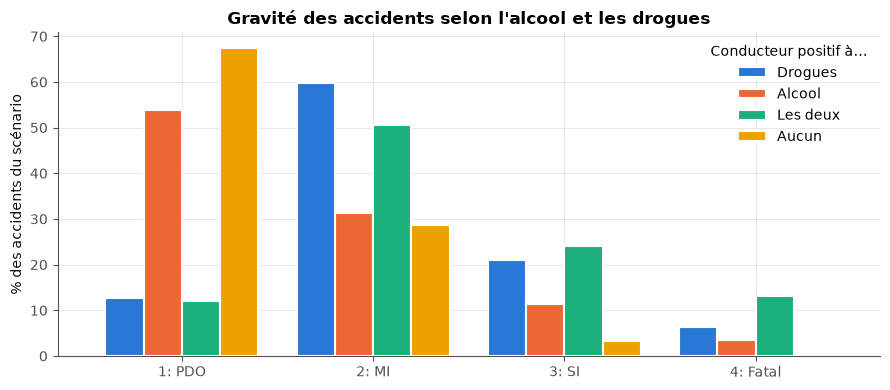

In [18]:
# On agrège dans Spark, puis on ne convertit en pandas que le petit résultat (4 x 5 valeurs)
pdf = pct_table.toPandas().set_index("CSEF Severity")
ax = pdf.plot.bar(rot=0, color=PALETTE, width=0.8, edgecolor="white", linewidth=1.5)
ax.set_ylabel("% des accidents du scénario"); ax.set_xlabel("")
ax.set_title("Gravité des accidents selon l'alcool et les drogues")
ax.legend(title="Conducteur positif à…", frameon=False)
plt.tight_layout(); plt.show()

**Lecture**
- Sans alcool ni drogue, **0,4 %** des accidents sont mortels. Ce taux passe à **3,4 %** avec de l'alcool, **6,3 %** avec des drogues et **13 %** avec les deux : il est multiplié par plus de 30.
- La part d'accidents purement matériels (PDO) s'effondre avec les drogues : 13 % contre 67 % sans substance.

⚠️ **Attention à l'interprétation** : c'est une **corrélation**, pas une preuve de causalité. Il existe un **biais de sélection** : les dépistages (surtout de drogues) sont plus systématiques lors des accidents graves. Les accidents graves ont donc mécaniquement plus de chances d'avoir un résultat positif enregistré.

## A.4 Une même requête, trois API : RDD, DataFrame, Spark SQL

**Spark SQL** permet d'interroger un DataFrame en SQL après l'avoir déclaré comme **vue temporaire**. On réécrit deux requêtes du dépôt dans les trois API et on **vérifie que les résultats sont identiques**.

### Requête 1 — Date, heure, victimes, sexe, âge et type de permis des unités impliquées dans un accident à `ADELAIDE`
La date est au format `Année-Mois-JourDeLaSemaine`, car le jour exact n'est pas publié.

In [19]:
# --- RDD : jointure de deux RDD clé-valeur (clé = REPORT_ID)
units_kv = units_rows.map(lambda r: (r[U["REPORT_ID"]], r))
crash_kv = crash_rows.map(lambda r: (r[K["REPORT_ID"]], r))

def ligne_adelaide(kv):
    _, (u, c) = kv
    if c[K["Suburb"]] == "ADELAIDE":
        yield (f'{c[K["Year"]]}-{c[K["Month"]]}-{c[K["Day"]]}', c[K["Time"]], c[K["Total Cas"]],
               u[U["Sex"]], u[U["Age"]], u[U["Licence Type"]])

q1_rdd = units_kv.join(crash_kv).flatMap(ligne_adelaide)

# --- DataFrame
q1_df = (complet_df.filter(F.col("Suburb") == "ADELAIDE")
         .select(F.concat_ws("-", "Year", "Month", "Day").alias("Date"), "Time", "Total Cas", "Sex", "Age", "Licence Type"))

# --- Spark SQL
units_df.createOrReplaceTempView("units")
crash_df.createOrReplaceTempView("crash")
q1_sql = spark.sql('''
    SELECT concat_ws('-', c.Year, c.Month, c.Day) AS Date, c.Time, c.`Total Cas`, u.Sex, u.Age, u.`Licence Type`
    FROM units u JOIN crash c ON u.REPORT_ID = c.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
''')

print(f"RDD : {q1_rdd.count():,} lignes | DataFrame : {q1_df.count():,} | SQL : {q1_sql.count():,}")
q1_sql.show(5)

RDD : 11,965 lignes | DataFrame : 11,965 | SQL : 11,965
+-------------------+--------+---------+------+----+-------------+
|               Date|    Time|Total Cas|   Sex| Age| Licence Type|
+-------------------+--------+---------+------+----+-------------+
|2012-January-Monday|08:45 am|        0|  Male|  84|         Full|
|2012-January-Monday|08:45 am|        0|  Male|  40|         Full|
|2012-January-Friday|05:45 pm|        0|  Male|  47|         Full|
|2012-January-Friday|05:45 pm|        0|  Male|NULL|         NULL|
|2012-January-Friday|07:30 pm|        1|Female|  18|Provisional 2|
+-------------------+--------+---------+------+----+-------------+
only showing top 5 rows



### Requête 2 — Total des victimes par quartier, conducteur sans permis

⚠️ **Correction n°2** : dans le dépôt, cette requête donne **trois résultats différents** selon l'API. Les versions RDD/DataFrame/SQL filtrent en réalité les conducteurs *avec* un permis connu, la version DataFrame **compte** les lignes au lieu de **sommer** les victimes, et la version RDD souffre du découpage décalé. On utilise ici la même définition que la requête 4 de la partie A.2, dans les trois API.

In [20]:
def meme_resultat(*dicts):
    "Compare des dict {clé: valeur} : NULL et '' sont assimilés, tolérance de 0.01 sur les nombres."
    norm = [{("" if k is None else k): v for k, v in d.items()} for d in dicts]
    ref = norm[0]
    return all(d.keys() == ref.keys() and all(abs(d[k] - ref[k]) <= 0.01 for k in ref) for d in norm[1:])

# --- RDD
def victimes_sans_permis(kv):
    _, (u, c) = kv
    if u[U["Licence Type"]] == "Unlicenced" and c[K["Total Cas"]].isdigit():
        yield (c[K["Suburb"]], int(c[K["Total Cas"]]))

q2_rdd = units_kv.join(crash_kv).flatMap(victimes_sans_permis).reduceByKey(lambda a, b: a + b)

# --- DataFrame
q2_df = (complet_df.filter(F.col("Licence Type") == "Unlicenced")
         .groupBy("Suburb").agg(F.sum("Total Cas").alias("victimes")))

# --- Spark SQL
q2_sql = spark.sql('''
    SELECT c.Suburb, SUM(c.`Total Cas`) AS victimes
    FROM units u JOIN crash c ON u.REPORT_ID = c.REPORT_ID
    WHERE u.`Licence Type` = 'Unlicenced'
    GROUP BY c.Suburb
''')

r_rdd = dict(q2_rdd.collect())
r_df  = {r["Suburb"]: r["victimes"] for r in q2_df.collect()}
r_sql = {r["Suburb"]: r["victimes"] for r in q2_sql.collect()}
assert meme_resultat(r_rdd, r_df, r_sql), "Les trois API ne donnent pas le même résultat !"
print(f"✅ Résultats identiques dans les 3 API ({len(r_df)} quartiers)")
print("Top 5 :", sorted(r_df.items(), key=lambda kv: -kv[1])[:5])

✅ Résultats identiques dans les 3 API (752 quartiers)
Top 5 : [('ADELAIDE', 43), ('SALISBURY', 30), ('PROSPECT', 27), ('INGLE FARM', 22), ('SALISBURY EAST', 20)]


---
# Partie B — Benchmark : RDD vs DataFrame vs Spark SQL

**Question** : à résultat identique, quelle API est la plus rapide, et pourquoi ?

**Protocole**
- 3 requêtes de complexité croissante, écrites dans les 3 API ;
- chaque mesure part des **fichiers CSV sur disque** (pas de cache), pour comparer des traitements complets ;
- 1 exécution d'échauffement (démarrage de la JVM, compilation du code), puis la **médiane** de `N_REPET` exécutions ;
- vérification systématique que les 3 API renvoient le même résultat.

| Requête | Opérations |
|---|---|
| **Q1 — Agrégation simple** | nombre d'accidents par niveau de gravité |
| **Q2 — Agrégation numérique** | âge moyen par sexe |
| **Q3 — Jointure + agrégation** | victimes par quartier, conducteur sans permis |

In [21]:
N_REPET = 3

def chrono(fonction, n=N_REPET):
    "Échauffement puis médiane de n exécutions. Renvoie (résultat, secondes)."
    resultat = fonction()
    durees = []
    for _ in range(n):
        t0 = time.perf_counter(); resultat = fonction(); durees.append(time.perf_counter() - t0)
    return resultat, statistics.median(durees)

# ---------- Les 3 requêtes x 3 API. Chaque fonction relit les fichiers et renvoie un dict.
def lignes_rdd(chemin):
    brut = spark.sparkContext.textFile(chemin)
    entete = brut.first()
    return brut.filter(lambda l: l != entete).mapPartitions(csv.reader)

def q1_rdd():
    return dict(lignes_rdd(CRASH_PATH).map(lambda r: (r[K["CSEF Severity"]], 1))
                .reduceByKey(lambda a, b: a + b).collect())

def q1_df():
    return {r[0]: r[1] for r in lire_csv(CRASH_PATH).groupBy("CSEF Severity").count().collect()}

def q1_sql():
    lire_csv(CRASH_PATH).createOrReplaceTempView("crash_b")
    return {r[0]: r[1] for r in spark.sql("SELECT `CSEF Severity`, COUNT(*) FROM crash_b GROUP BY 1").collect()}

def q2_rdd():
    return dict(lignes_rdd(UNITS_PATH).flatMap(sexe_age)
                .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                .mapValues(lambda s: round(s[0] / s[1], 2)).collect())

def q2_df():
    u = lire_csv(UNITS_PATH).withColumn("Age", en_entier("Age"))
    return {r[0]: float(r[1]) for r in u.filter(F.col("Sex").isin("Male", "Female") & F.col("Age").isNotNull())
            .groupBy("Sex").agg(F.round(F.avg("Age"), 2)).collect()}

def q2_sql():
    lire_csv(UNITS_PATH).createOrReplaceTempView("units_b")
    return {r[0]: float(r[1]) for r in spark.sql('''
        SELECT Sex, ROUND(AVG(CAST(trim(Age) AS INT)), 2) FROM units_b
        WHERE Sex IN ('Male', 'Female') AND trim(Age) RLIKE '^[0-9]+$' GROUP BY Sex''').collect()}

def q3_rdd():
    u = lignes_rdd(UNITS_PATH).map(lambda r: (r[U["REPORT_ID"]], r))
    c = lignes_rdd(CRASH_PATH).map(lambda r: (r[K["REPORT_ID"]], r))
    return dict(u.join(c).flatMap(victimes_sans_permis).reduceByKey(lambda a, b: a + b).collect())

def q3_df_plan():
    u, c = lire_csv(UNITS_PATH), lire_csv(CRASH_PATH).withColumn("Total Cas", en_entier("Total Cas"))
    return (u.join(c, "REPORT_ID").filter(F.col("Licence Type") == "Unlicenced")
            .groupBy("Suburb").agg(F.sum("Total Cas").alias("victimes")))

def q3_sql_plan():
    # Les vues exposent les mêmes colonnes typées que la version DataFrame
    lire_csv(UNITS_PATH).createOrReplaceTempView("units_b")
    lire_csv(CRASH_PATH).withColumn("Total Cas", en_entier("Total Cas")).createOrReplaceTempView("crash_b")
    return spark.sql('''
        SELECT c.Suburb, SUM(c.`Total Cas`) AS victimes
        FROM units_b u JOIN crash_b c ON u.REPORT_ID = c.REPORT_ID
        WHERE u.`Licence Type` = 'Unlicenced' GROUP BY c.Suburb''')

q3_df  = lambda: {r[0]: r[1] for r in q3_df_plan().collect()}
q3_sql = lambda: {r[0]: r[1] for r in q3_sql_plan().collect()}

REQUETES = {
    "Q1 Agrégation simple":     {"RDD": q1_rdd, "DataFrame": q1_df, "SQL": q1_sql},
    "Q2 Agrégation numérique":  {"RDD": q2_rdd, "DataFrame": q2_df, "SQL": q2_sql},
    "Q3 Jointure + agrégation": {"RDD": q3_rdd, "DataFrame": q3_df, "SQL": q3_sql},
}

In [22]:
mesures = []
for requete, apis in REQUETES.items():
    resultats = {}
    for api, f in apis.items():
        resultats[api], duree = chrono(f)
        mesures.append({"Requête": requete, "API": api, "Temps (s)": duree})
        print(f"{requete:26s} | {api:9s} : {duree:6.2f} s")
    assert meme_resultat(resultats["RDD"], resultats["DataFrame"], resultats["SQL"]), f"Résultats différents pour {requete}"
print("\n✅ Pour chaque requête, les 3 API renvoient exactement le même résultat")

bench = pd.DataFrame(mesures).pivot(index="Requête", columns="API", values="Temps (s)")[["RDD", "DataFrame", "SQL"]]
bench["RDD / DataFrame"] = (bench["RDD"] / bench["DataFrame"]).round(1)
bench.round(2)

Q1 Agrégation simple       | RDD       :   0.15 s
Q1 Agrégation simple       | DataFrame :   0.12 s
Q1 Agrégation simple       | SQL       :   0.11 s
Q2 Agrégation numérique    | RDD       :   0.18 s
Q2 Agrégation numérique    | DataFrame :   0.14 s
Q2 Agrégation numérique    | SQL       :   0.11 s
Q3 Jointure + agrégation   | RDD       :   0.99 s
Q3 Jointure + agrégation   | DataFrame :   0.30 s
Q3 Jointure + agrégation   | SQL       :   0.29 s

✅ Pour chaque requête, les 3 API renvoient exactement le même résultat


API,RDD,DataFrame,SQL,RDD / DataFrame
Requête,,,,
Q1 Agrégation simple,0.15,0.12,0.11,1.2
Q2 Agrégation numérique,0.18,0.14,0.11,1.3
Q3 Jointure + agrégation,0.99,0.30,0.29,3.3


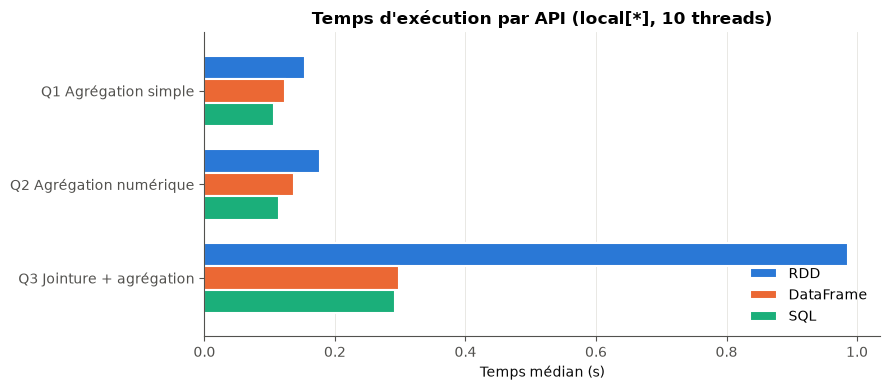

In [23]:
ax = bench[["RDD", "DataFrame", "SQL"]].plot.barh(color=PALETTE[:3], width=0.75, edgecolor="white", linewidth=1.5)
ax.invert_yaxis(); ax.set_xlabel("Temps médian (s)"); ax.set_ylabel("")
ax.set_title(f"Temps d'exécution par API ({sc.master}, {sc.defaultParallelism} threads)")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### B.2 Pourquoi DataFrame et SQL vont au même rythme : le plan d'exécution
DataFrame et SQL ne sont que deux façons d'écrire la même requête. Les deux passent par l'optimiseur **Catalyst**, qui produit le même plan physique, c'est-à-dire les opérations réellement exécutées.

In [24]:
plan_df, plan_sql = q3_df_plan(), q3_sql_plan()
plan_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Suburb#5285], functions=[sum(Total Cas#5349)])
   +- Exchange hashpartitioning(Suburb#5285, 200), ENSURE_REQUIREMENTS, [plan_id=5289]
      +- HashAggregate(keys=[Suburb#5285], functions=[partial_sum(Total Cas#5349)])
         +- Project [Suburb#5285, Total Cas#5349]
            +- BroadcastHashJoin [REPORT_ID#5230], [REPORT_ID#5283], Inner, BuildLeft, false
               :- BroadcastExchange HashedRelationBroadcastMode(List(input[0, string, true]),false), [plan_id=5284]
               :  +- Project [REPORT_ID#5230]
               :     +- Filter ((isnotnull(Licence Type#5241) AND (Licence Type#5241 = Unlicenced)) AND isnotnull(REPORT_ID#5230))
               :        +- FileScan csv [REPORT_ID#5230,Licence Type#5241] Batched: false, DataFilters: [isnotnull(Licence Type#5241), (Licence Type#5241 = Unlicenced), isnotnull(REPORT_ID#5230)], Format: CSV, Location: InMemoryFileIndex(8 paths)[file:/Users/batistau

**Comment lire ce plan** (de bas en haut) :
- `FileScan csv … ReadSchema` : Spark ne lit **que les colonnes nécessaires** (*column pruning*) ;
- `PushedFilters: [EqualTo(Licence Type,Unlicenced)]` : le filtre est appliqué **dès la lecture** (*predicate pushdown*), avant la jointure ;
- `BroadcastHashJoin` : le petit côté de la jointure (les conducteurs sans permis) est **copié sur chaque executor**. On évite ainsi de redistribuer les 127 000 accidents ;
- `HashAggregate (partial)` puis `Exchange` puis `HashAggregate (final)` : pré-agrégation locale, shuffle, puis agrégation finale. C'est le schéma MapReduce avec Combiner.

Le RDD, lui, exécute **exactement** ce qu'on a écrit : il découpe toutes les colonnes de toutes les lignes en Python, joint les 272 000 unités aux 127 000 accidents, puis filtre. Aucune de ces optimisations n'est possible.

In [25]:
import re
def plan_physique(df):
    "Plan physique en texte, sans les identifiants internes (#123, plan_id=...) qui changent à chaque requête."
    return re.sub(r"#\d+|plan_id=\d+", "", df._jdf.queryExecution().executedPlan().toString())

print("Plan physique SQL identique au plan DataFrame :", plan_physique(plan_df) == plan_physique(plan_sql))
print("Le RDD n'a pas de plan optimisé, seulement sa lignée (lineage) :")
print(lignes_rdd(UNITS_PATH).flatMap(sexe_age).reduceByKey(lambda a, b: a).toDebugString().decode())

Plan physique SQL identique au plan DataFrame : True
Le RDD n'a pas de plan optimisé, seulement sa lignée (lineage) :
(8) PythonRDD[989] at RDD at PythonRDD.scala:53 []
 |  MapPartitionsRDD[988] at mapPartitions at PythonRDD.scala:160 []
 |  ShuffledRDD[987] at partitionBy at <unknown>:0 []
 +-(8) PairwiseRDD[986] at reduceByKey at /var/folders/1s/4qln7b850mj8d7n6b338c6dw0000gn/T/ipykernel_95722/3721840528.py:8 []
    |  PythonRDD[985] at reduceByKey at /var/folders/1s/4qln7b850mj8d7n6b338c6dw0000gn/T/ipykernel_95722/3721840528.py:8 []
    |  units_data/*.csv MapPartitionsRDD[983] at textFile at <unknown>:0 []
    |  units_data/*.csv HadoopRDD[982] at textFile at <unknown>:0 []


### B.3 Effet du nombre de cœurs
On relance Spark avec 1, 2, 4… threads et on mesure la requête la plus lourde (Q3). L'**accélération** (*speedup*) vaut `temps avec 1 cœur / temps avec n cœurs`. Dans l'idéal, elle vaut `n`.

Ici, n vaut au maximum 10 car mon Mac a 10 coeurs.

In [26]:
nb_coeurs_max = os.cpu_count()
CONFIGS = sorted({1, 2, 4, nb_coeurs_max} & set(range(1, nb_coeurs_max + 1)))

scaling = []
for n in CONFIGS:
    spark.stop()
    spark = creer_spark(f"local[{n}]"); sc = spark.sparkContext
    for api, f in REQUETES["Q3 Jointure + agrégation"].items():
        _, duree = chrono(f, n=2)
        scaling.append({"Cœurs": n, "API": api, "Temps (s)": duree})
        print(f"{n:2d} cœur(s) | {api:9s} : {duree:6.2f} s")

spark.stop(); spark = creer_spark(); sc = spark.sparkContext      # retour à local[*]
crash_df, units_df = charger_dataframes()   # les DataFrames de l'ancienne session ne sont plus utilisables

sc_df = pd.DataFrame(scaling).pivot(index="Cœurs", columns="API", values="Temps (s)")[["RDD", "DataFrame", "SQL"]]
speedup = sc_df.iloc[0] / sc_df
display(sc_df.round(2)); display(speedup.round(2).add_suffix(" speedup"))

 1 cœur(s) | RDD       :   2.69 s
 1 cœur(s) | DataFrame :   0.45 s
 1 cœur(s) | SQL       :   0.41 s
 2 cœur(s) | RDD       :   1.49 s
 2 cœur(s) | DataFrame :   0.31 s
 2 cœur(s) | SQL       :   0.30 s
 4 cœur(s) | RDD       :   0.94 s
 4 cœur(s) | DataFrame :   0.28 s
 4 cœur(s) | SQL       :   0.24 s
10 cœur(s) | RDD       :   0.84 s
10 cœur(s) | DataFrame :   0.29 s
10 cœur(s) | SQL       :   0.25 s


API,RDD,DataFrame,SQL
Cœurs,,,
1,2.69,0.45,0.41
2,1.49,0.31,0.30
4,0.94,0.28,0.24
10,0.84,0.29,0.25


API,RDD speedup,DataFrame speedup,SQL speedup
Cœurs,,,
1,1.00,1.00,1.00
2,1.81,1.46,1.37
4,2.86,1.62,1.72
10,3.19,1.56,1.65


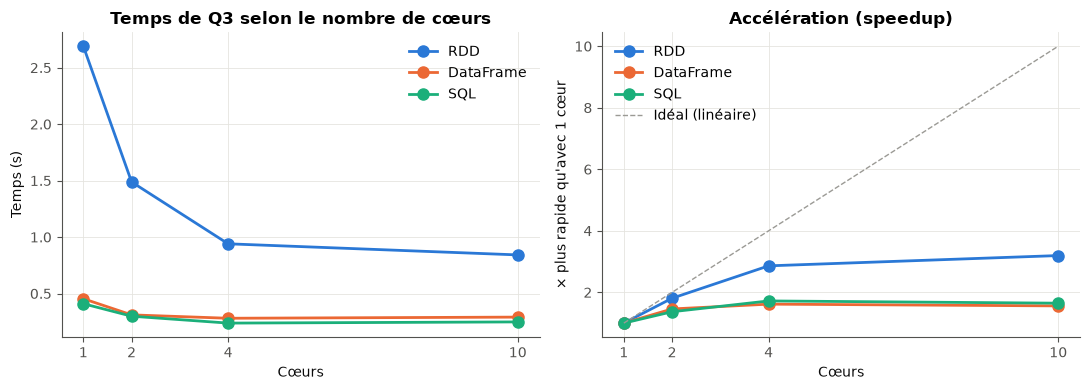

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for (api, s), coul in zip(sc_df.items(), PALETTE):
    a1.plot(s.index, s.values, marker="o", lw=2, ms=8, color=coul, label=api)
    a2.plot(speedup.index, speedup[api], marker="o", lw=2, ms=8, color=coul, label=api)
a2.plot(CONFIGS, CONFIGS, ls="--", color="#9b9a95", lw=1, label="Idéal (linéaire)")
a1.set(title="Temps de Q3 selon le nombre de cœurs", xlabel="Cœurs", ylabel="Temps (s)", xticks=CONFIGS)
a2.set(title="Accélération (speedup)", xlabel="Cœurs", ylabel="× plus rapide qu'avec 1 cœur", xticks=CONFIGS)
a1.legend(frameon=False); a2.legend(frameon=False)
plt.tight_layout(); plt.show()

### B.4 Effet du nombre de partitions de shuffle
Après un `groupBy` ou une jointure, Spark redistribue les données en `spark.sql.shuffle.partitions` partitions (200 par défaut). Chaque partition devient une **tâche**, avec un coût fixe de planification.

Pour voir l'effet brut, on désactive l'**AQE** (*Adaptive Query Execution*). C'est le mécanisme qui, depuis Spark 3, fusionne automatiquement les partitions trop petites.

    1 partitions :  0.22 s
    4 partitions :  0.21 s
    8 partitions :  0.19 s
   50 partitions :  0.40 s
  200 partitions :  0.96 s
 1000 partitions :  1.53 s


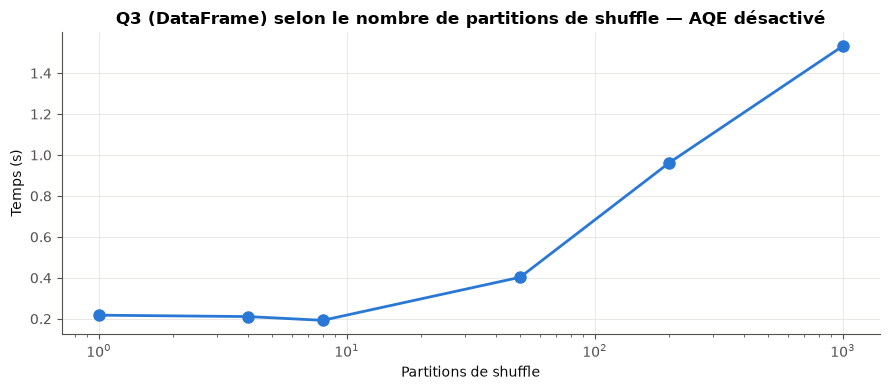

In [28]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")   # force un vrai shuffle des deux côtés de la jointure

part = []
for n in [1, 4, 8, 50, 200, 1000]:
    spark.conf.set("spark.sql.shuffle.partitions", str(n))
    _, duree = chrono(q3_df, n=2)
    part.append({"Partitions de shuffle": n, "Temps (s)": duree})
    print(f"{n:5d} partitions : {duree:5.2f} s")

for cle in ["spark.sql.adaptive.enabled", "spark.sql.autoBroadcastJoinThreshold", "spark.sql.shuffle.partitions"]:
    spark.conf.unset(cle)                                           # retour aux valeurs par défaut

part_df = pd.DataFrame(part).set_index("Partitions de shuffle")
ax = part_df.plot(marker="o", lw=2, ms=8, color=BLEU, legend=False, logx=True)
ax.set(title="Q3 (DataFrame) selon le nombre de partitions de shuffle — AQE désactivé", ylabel="Temps (s)")
plt.tight_layout(); plt.show()

Lorsqu'il faut faire de nombreuses partitions, l'effet brut nous permet de constate que le coût du temps de partitionnnement devient important d'où l'utilisation de l'AQE qui permet d'optimiser le plan d'exécution.

### B.5 Synthèse du benchmark

> Mesures obtenues sur le Mac (10 cœurs, médiane de 3 essais) : sur la jointure Q3, RDD 0,84 s, DataFrame 0,27 s et SQL 0,28 s (RDD 3,1 fois plus lent) ; avec 10 cœurs au lieu d'1, le RDD est accéléré 3 fois et les DataFrame/SQL 1,3 à 1,6 fois ; Q3 prend 0,19 s avec 4 à 8 partitions de shuffle contre 1,5 s avec 1 000. Les chiffres varient légèrement d'une exécution à l'autre.

| | RDD | DataFrame | Spark SQL |
|---|---|---|---|
| **Niveau d'abstraction** | Bas : objets Python, on décrit *comment* calculer | Haut : colonnes typées, on décrit *quoi* calculer | Haut : requête SQL déclarative |
| **Optimisation** | Aucune : exécute le code tel quel | Catalyst + moteur Tungsten | Identique au DataFrame (même plan) |
| **Exécution du code** | Python, avec aller-retour JVM ↔ Python pour chaque ligne | Entièrement dans la JVM | Entièrement dans la JVM |
| **Performance mesurée** | La plus lente, surtout avec jointure | Rapide | Rapide, égale au DataFrame |
| **Quand l'utiliser** | Données non structurées, logique impossible à exprimer en colonnes | Cas général en Python | Analystes SQL, requêtes complexes lisibles |

**À retenir**
1. **DataFrame = SQL** en performance : même optimiseur, même plan. Le choix est une question de lisibilité.
2. **Le RDD est plus lent** pour deux raisons : aucune optimisation (pas de filtre poussé à la lecture, pas de sélection de colonnes, pas de *broadcast join*) et le coût de la sérialisation entre la JVM et Python. L'écart est le plus grand sur la jointure.
3. **Ajouter des cœurs aide, mais moins que l'idéal** : coûts fixes (lecture, planification, shuffle) et seulement 16 fichiers à lire. Sur 80 Mo, on est loin des volumes où le parallélisme donne sa pleine mesure.
4. **Le nombre de partitions est un réglage important** : trop peu, et on n'exploite pas tous les cœurs ; beaucoup trop, et le coût des milliers de petites tâches domine. L'AQE règle ce problème automatiquement, d'où l'intérêt de le laisser activé.

---
# Partie C — Nouvelles analyses

**Question directrice** : *quand, où et dans quelles conditions les accidents sont-ils les plus graves ?*

On définit un **accident grave** comme un accident avec au moins un blessé grave ou un mort (`3: SI` ou `4: Fatal`). L'indicateur principal est le **taux d'accidents graves** = accidents graves / total des accidents. Un simple nombre d'accidents ne suffit pas : il reflète surtout le trafic, pas le danger.

Méthode : tous les calculs lourds sont faits **dans Spark**. On ne convertit en pandas que les **petits résultats agrégés** à tracer.

In [29]:
# Colonnes dérivées, calculées une fois et mises en cache (réutilisées par toutes les analyses)
heure_txt = F.col("Time")
heure = (F.substring(heure_txt, 1, 2).cast("int") % 12) + F.when(F.lower(heure_txt).endswith("pm"), 12).otherwise(0)

JOURS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MOIS  = ["January", "February", "March", "April", "May", "June", "July",
         "August", "September", "October", "November", "December"]

acc = (crash_df
       .withColumn("Heure", heure)
       .withColumn("Grave", F.col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int"))
       .withColumn("Mortel", (F.col("CSEF Severity") == "4: Fatal").cast("int"))
       .cache())

def taux(df, *cles, min_n=0):
    "Nombre d'accidents, taux d'accidents graves et mortels (en %) par modalité."
    return (df.groupBy(*cles)
              .agg(F.count("*").alias("Accidents"),
                   F.round(100 * F.avg("Grave"), 2).alias("% graves"),
                   F.round(100 * F.avg("Mortel"), 2).alias("% mortels"))
              .filter(F.col("Accidents") >= min_n))

taux_global = acc.agg(F.avg("Grave")).first()[0] * 100
print(f"{acc.count():,} accidents | taux global d'accidents graves : {taux_global:.2f} %")

127,672 accidents | taux global d'accidents graves : 4.38 %


## C.1 Quand ? — Heure, jour et mois

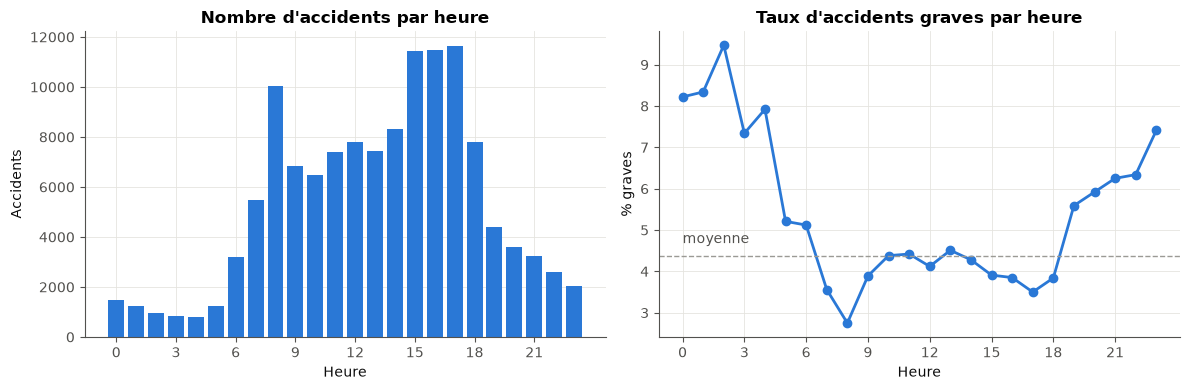

In [30]:
par_heure = taux(acc, "Heure").orderBy("Heure").toPandas().set_index("Heure")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(par_heure.index, par_heure["Accidents"], color=BLEU, width=0.8)
a1.set(title="Nombre d'accidents par heure", xlabel="Heure", ylabel="Accidents", xticks=range(0, 24, 3))
a2.plot(par_heure.index, par_heure["% graves"], marker="o", ms=6, lw=2, color=BLEU)
a2.axhline(taux_global, ls="--", lw=1, color="#9b9a95"); a2.text(0, taux_global + 0.3, "moyenne", color="#52514e")
a2.set(title="Taux d'accidents graves par heure", xlabel="Heure", ylabel="% graves", xticks=range(0, 24, 3))
plt.tight_layout(); plt.show()

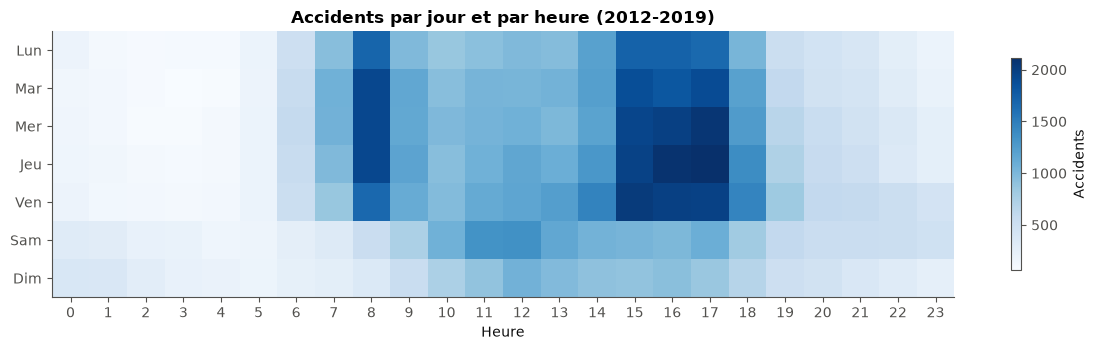

,Accidents,% graves,% mortels
Day,,,
Monday,17681,4.09,0.57
Tuesday,19317,3.89,0.49
Wednesday,20159,3.83,0.45
Thursday,20799,3.76,0.42
Friday,21249,4.19,0.53
Saturday,15693,5.53,0.78
Sunday,12774,6.33,0.90


In [31]:
# Carte de chaleur jour x heure (nombre d'accidents)
grille = (acc.groupBy("Day", "Heure").count().toPandas()
          .pivot(index="Day", columns="Heure", values="count").reindex(JOURS).fillna(0))

fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(grille.values, aspect="auto", cmap="Blues")
ax.set(yticks=range(7), yticklabels=["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"],
       xticks=range(24), xlabel="Heure", title="Accidents par jour et par heure (2012-2019)")
ax.grid(False); fig.colorbar(im, ax=ax, label="Accidents", shrink=0.8)
plt.tight_layout(); plt.show()

taux(acc, "Day").toPandas().set_index("Day").reindex(JOURS)

In [32]:
taux(acc, "Month").toPandas().set_index("Month").reindex(MOIS).T

Month,January,February,March,April,May,June,July,August,September,October,November,December
Accidents,9350.00,10382.00,11474.00,10042.00,11745.00,10714.00,10470.00,10965.00,10228.00,10784.00,10679.00,10839.00
% graves,4.52,3.85,4.79,4.70,4.31,3.98,4.19,4.35,4.20,4.44,4.64,4.61
% mortels,0.63,0.35,0.66,0.57,0.48,0.56,0.53,0.53,0.53,0.63,0.64,0.69


**Lecture**
- Le **nombre** d'accidents suit le trafic : pics aux heures de pointe (8 h et 15-17 h) en semaine, fin de matinée et après-midi le week-end.
- La **gravité** suit la tendance inverse. Entre 19 h et 4 h, il y a peu d'accidents, mais 5,6 à 9,5 % sont graves (maximum à 2 h), contre 2,8 % à l'heure de pointe de 8 h. Plusieurs facteurs se cumulent : vitesse sur routes dégagées, fatigue, alcool, visibilité.
- Le **week-end** compte moins d'accidents mais plus graves : environ 5,5 % le samedi et 6,3 % le dimanche, contre environ 4 % en semaine.
- La saisonnalité mensuelle est faible : de 3,9 % à 4,8 % selon le mois.

## C.2 Évolution 2012-2019

,Accidents,Décès,Blessés graves,% graves
Year,,,,
2012,22829,94,761,3.17
2013,16675,97,790,4.53
2014,16162,108,711,4.27
2015,15431,102,759,4.88
2016,16775,86,692,3.88
2017,13237,100,622,4.73
2018,13599,80,576,4.12
2019,12964,114,833,6.47


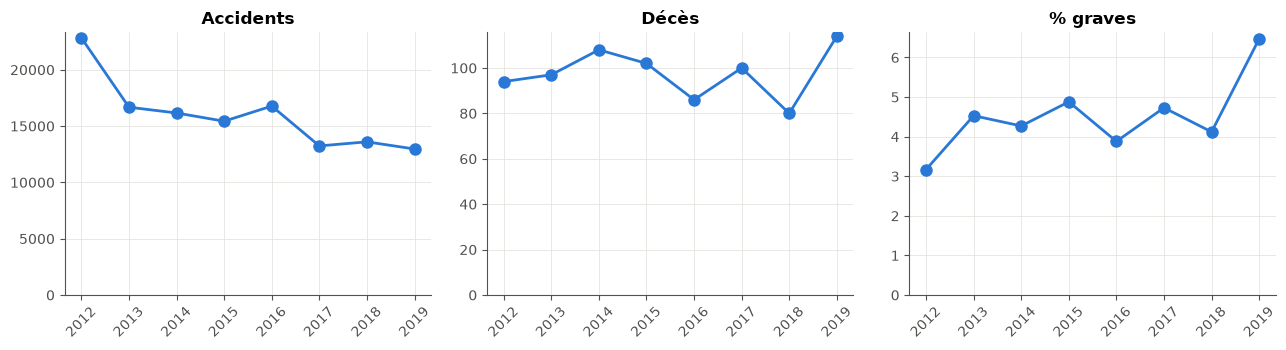

In [33]:
annuel = (acc.groupBy("Year")
          .agg(F.count("*").alias("Accidents"), F.sum("Total Fats").alias("Décès"),
               F.sum("Total SI").alias("Blessés graves"), F.round(100 * F.avg("Grave"), 2).alias("% graves"))
          .orderBy("Year").toPandas().set_index("Year"))
display(annuel)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Accidents", "Décès", "% graves"]):
    ax.plot(annuel.index, annuel[col], marker="o", ms=8, lw=2, color=BLEU)
    ax.set(title=col, xticks=annuel.index); ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

**Lecture**
- Le nombre d'accidents enregistrés **baisse d'environ 43 %** entre 2012 et 2019 (22 829 → 12 964). ⚠️ La chute brutale entre 2012 et 2013 (−27 % en un an) est suspecte : elle peut refléter un **changement de règles de déclaration** (par exemple pour les accidents purement matériels) plutôt qu'une vraie baisse. À vérifier dans le fichier de métadonnées avant de conclure.
- Le nombre de **décès** ne baisse pas : il oscille entre 80 et 114 par an. Comme le nombre total d'accidents diminue, la **part d'accidents graves tend à augmenter** (3,2 % en 2012, 6,5 % en 2019). C'est cohérent avec l'hypothèse d'une baisse des déclarations d'accidents légers.

C'est un bon exemple de l'intérêt du taux par rapport au simple comptage, et de la prudence nécessaire face à des données administratives.

## C.3 Dans quelles conditions ? — Vitesse, météo, luminosité, route

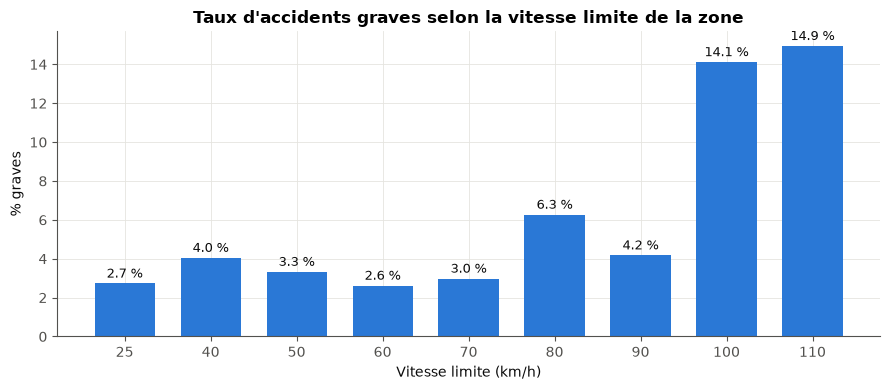

,Area Speed,Accidents,% graves,% mortels
0,25,476,2.73,1.05
1,40,1852,4.05,0.32
2,50,34244,3.33,0.27
3,60,61035,2.62,0.23
4,70,4026,2.98,0.30
5,80,11013,6.27,0.74
6,90,2106,4.18,0.85
7,100,7413,14.12,2.29
8,110,5359,14.95,3.38


In [34]:
vitesse = taux(acc.filter(F.col("Area Speed").isNotNull()), "Area Speed", min_n=200).orderBy("Area Speed").toPandas()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(vitesse["Area Speed"].astype(str), vitesse["% graves"], color=BLEU, width=0.7)
for x, (t, n) in enumerate(zip(vitesse["% graves"], vitesse["Accidents"])):
    ax.text(x, t + 0.3, f"{t:.1f} %", ha="center", fontsize=9, color="#0b0b0b")
ax.set(title="Taux d'accidents graves selon la vitesse limite de la zone",
       xlabel="Vitesse limite (km/h)", ylabel="% graves")
plt.tight_layout(); plt.show()
vitesse

In [35]:
CONDITIONS = ["DayNight", "Weather Cond", "Road Surface", "Moisture Cond", "Horizontal Align", "Stats Area"]
for col in CONDITIONS:
    print(f"— {col}")
    taux(acc, col, min_n=100).orderBy(F.desc("% graves")).show(truncate=False)

— DayNight
+--------+---------+--------+---------+
|DayNight|Accidents|% graves|% mortels|
+--------+---------+--------+---------+
|Night   |28948    |5.9     |0.84     |
|Daylight|98724    |3.94    |0.48     |
+--------+---------+--------+---------+

— Weather Cond
+------------+---------+--------+---------+
|Weather Cond|Accidents|% graves|% mortels|
+------------+---------+--------+---------+
|Unknown     |448      |6.7     |1.12     |
|Not Raining |115956   |4.44    |0.59     |
|Raining     |11268    |3.75    |0.31     |
+------------+---------+--------+---------+

— Road Surface
+------------+---------+--------+---------+
|Road Surface|Accidents|% graves|% mortels|
+------------+---------+--------+---------+
|Unsealed    |3507     |13.69   |1.65     |
|Sealed      |124151   |4.12    |0.53     |
+------------+---------+--------+---------+

— Moisture Cond
+-------------+---------+--------+---------+
|Moisture Cond|Accidents|% graves|% mortels|
+-------------+---------+--------+----

**Lecture**
- **La vitesse est le facteur le plus marquant** : environ 14-15 % d'accidents graves dans les zones à 100-110 km/h, contre 2,6-3,3 % en ville à 50-60 km/h, soit environ 5 fois plus.
- **Zones rurales** (*Country* : 11,6 % contre 3,1 % en zone métropolitaine), **routes non goudronnées** (13,7 % contre 4,1 %), **virages** (9-11 % contre 3,7 % en ligne droite) et **nuit** (5,9 % contre 3,9 %) ont des taux de gravité nettement supérieurs.
- **Paradoxe de la pluie** : les accidents sous la pluie ne sont **pas** plus graves, et même un peu moins. Une explication probable : les conducteurs ralentissent, et la pluie multiplie surtout les petits accrochages urbains.

Ces facteurs sont **liés entre eux** (une route rurale est souvent à 100 km/h, non éclairée et sinueuse). Pour isoler l'effet propre de chacun, il faudrait un modèle multivarié, par exemple une régression logistique avec Spark MLlib.

## C.4 Qui ? — Âge, permis et type de véhicule

In [36]:
# On rattache à chaque unité la gravité de l'accident (jointure) et on garde les conducteurs (âge connu, permis renseigné)
unites = (units_df.join(acc.select("REPORT_ID", "Grave", "Mortel"), "REPORT_ID")
          .withColumn("Tranche d'âge", F.when(F.col("Age") < 17, "< 17")
                      .when(F.col("Age") < 25, "17-24").when(F.col("Age") < 40, "25-39")
                      .when(F.col("Age") < 60, "40-59").when(F.col("Age") < 75, "60-74")
                      .when(F.col("Age").isNotNull(), "75 +")))
conducteurs = unites.filter(F.col("Licence Type").isNotNull() & (F.col("Licence Type") != "Unknown"))

age = (taux(conducteurs.filter(F.col("Tranche d'âge").isNotNull()), "Tranche d'âge")
       .orderBy("Tranche d'âge").toPandas().set_index("Tranche d'âge"))
age = age.reindex(["< 17", "17-24", "25-39", "40-59", "60-74", "75 +"]).dropna()
display(age)

permis = taux(conducteurs, "Licence Type", min_n=50).orderBy(F.desc("% graves")).toPandas()
display(permis)

,Accidents,% graves,% mortels
Tranche d'âge,,,
< 17,642,8.72,0.47
17-24,42213,3.25,0.40
25-39,61501,3.08,0.39
40-59,63068,3.62,0.50
60-74,23606,4.22,0.65
75 +,8566,5.72,1.16


,Licence Type,Accidents,% graves,% mortels
0,Disqualified,428,11.92,3.04
1,Unlicenced,3926,9.76,1.76
2,Learners,2432,7.15,0.45
3,Conditional,68,5.88,0.00
4,Probationary,1162,4.22,0.69
5,Provisional 2,8663,3.45,0.35
6,Full,168865,3.36,0.48
7,Provisional 1,15657,3.23,0.28


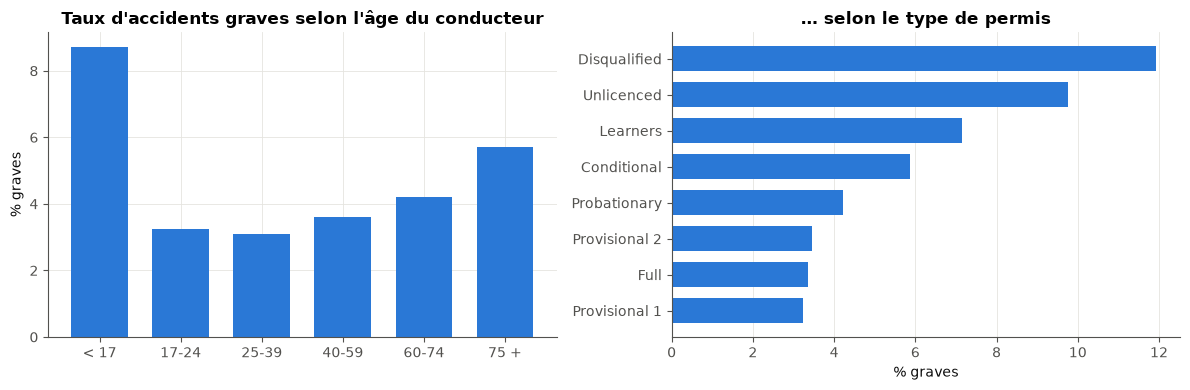

In [37]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(age.index, age["% graves"], color=BLEU, width=0.7)
a1.set(title="Taux d'accidents graves selon l'âge du conducteur", ylabel="% graves")
p = permis.sort_values("% graves")
a2.barh(p["Licence Type"].str.strip(), p["% graves"], color=BLEU, height=0.7)
a2.set(title="… selon le type de permis", xlabel="% graves"); a2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [38]:
# Types d'unités : fréquence et gravité (inclut piétons, cyclistes, obstacles fixes)
taux(unites, "Unit Type", min_n=1000).orderBy(F.desc("% mortels")).show(15, truncate=False)

+-----------------------------+---------+--------+---------+
|Unit Type                    |Accidents|% graves|% mortels|
+-----------------------------+---------+--------+---------+
|Pedestrian on Road           |2526     |21.38   |3.44     |
|Tree                         |7640     |12.8    |2.24     |
|Motor Cycle                  |6373     |17.35   |1.8      |
|Other Defined Special Vehicle|1085     |5.62    |1.75     |
|Guard Rail                   |1482     |9.38    |1.48     |
|SEMI TRAILER                 |2786     |5.89    |1.33     |
|Stobie Pole                  |2527     |7.84    |1.27     |
|Other Fixed Obstruction      |10074    |6.25    |0.85     |
|Sign Post                    |1028     |6.52    |0.78     |
|RIGID TRUCK LGE GE 4.5T      |5722     |2.81    |0.72     |
|Pedal Cycle                  |7194     |8.22    |0.57     |
|Utility                      |20800    |3.91    |0.56     |
|Station Wagon                |44209    |3.06    |0.42     |
|OMNIBUS                

**Lecture**
- **Les conducteurs suspendus ou sans permis** sont impliqués dans des accidents bien plus souvent graves : 11,9 % pour *Disqualified* et 9,8 % pour *Unlicenced*, contre 3,4 % pour un permis complet (*Full*). Ce sont aussi des profils associés à d'autres comportements à risque (vitesse, alcool, fuite).
- **Âge** : la gravité augmente avec l'âge, de 3,1 % chez les 25-39 ans à 5,7 % chez les 75 ans et plus, probablement à cause de la plus grande fragilité physique. Les **jeunes de 17-24 ans** n'ont pas des accidents plus graves, mais ils en ont **beaucoup plus** : environ 5 300 par année d'âge (42 213 sur 8 ans), contre environ 4 100 pour les 25-39 ans (61 501 sur 15 ans). Leur risque porte donc sur la **fréquence**, pas sur la gravité. Il faudrait rapporter ces chiffres au nombre de conducteurs de chaque âge pour conclure.
- Les usagers **vulnérables** (motos, piétons, cyclistes) et les **obstacles fixes** (arbres, poteaux, c'est-à-dire des sorties de route) sont associés aux taux de mortalité les plus forts.

## C.5 Où ? — Carte des accidents et points noirs
Les colonnes `ACCLOC_X` et `ACCLOC_Y` sont des coordonnées projetées en mètres (projection Lambert de l'Australie-Méridionale). On peut donc les tracer directement en nuage de points.

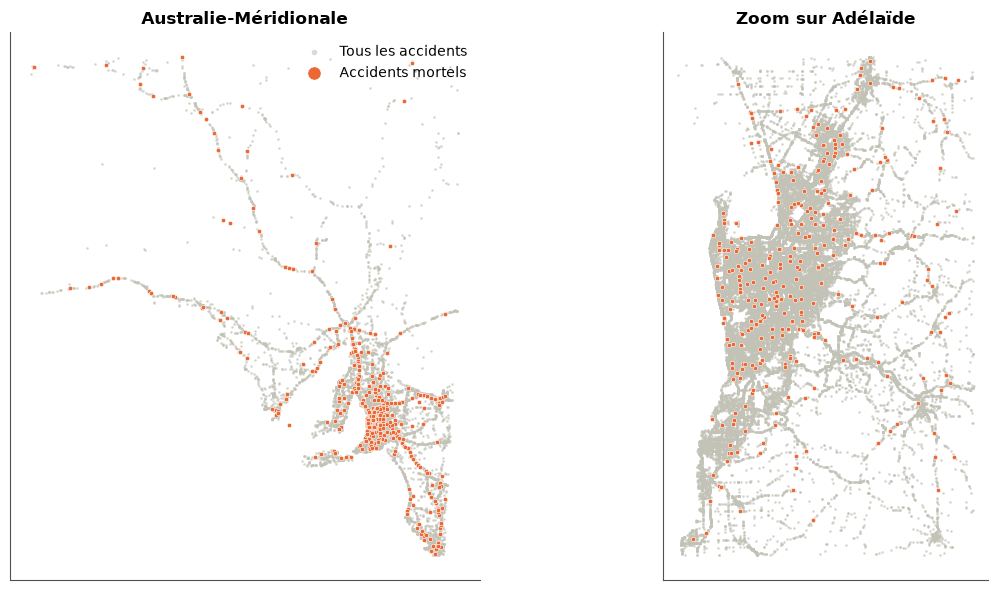

In [39]:
pts = (acc.filter(F.col("ACCLOC_X").isNotNull())
          .select(F.col("ACCLOC_X").cast("double").alias("x"), F.col("ACCLOC_Y").cast("double").alias("y"), "Grave", "Mortel")
          .toPandas())        # 2 colonnes x 124 000 lignes : quelques Mo, acceptable en mémoire

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6))
for ax, (titre, zoom) in zip([a1, a2], [("Australie-Méridionale", None),
                                       ("Zoom sur Adélaïde", (1300000, 1360000, 1630000, 1710000))]):
    d = pts if zoom is None else pts[pts.x.between(zoom[0], zoom[1]) & pts.y.between(zoom[2], zoom[3])]
    ax.scatter(d.x, d.y, s=1, color="#c3c2b7", alpha=0.5, label="Tous les accidents", rasterized=True)
    m = d[d.Mortel == 1]
    ax.scatter(m.x, m.y, s=10, color=PALETTE[1], edgecolor="white", linewidth=0.4, label="Accidents mortels")
    ax.set(title=titre, xticks=[], yticks=[], aspect="equal"); ax.grid(False)
a1.legend(frameon=False, loc="upper right", markerscale=3)
plt.tight_layout(); plt.show()

In [40]:
# Points noirs : lieux exacts (UNIQUE_LOC) cumulant le plus d'accidents graves
(acc.filter(F.col("Grave") == 1)
    .groupBy("UNIQUE_LOC", "Suburb")
    .agg(F.count("*").alias("Accidents graves"), F.sum("Total Fats").alias("Décès"))
    .orderBy(F.desc("Accidents graves")).show(10))

print("Quartiers avec le plus d'accidents graves :")
taux(acc, "Suburb").withColumn("Accidents graves", F.round(F.col("Accidents") * F.col("% graves") / 100).cast("int")) \
    .orderBy(F.desc("Accidents graves")).show(10)

+--------------+----------------+----------------+-----+
|    UNIQUE_LOC|          Suburb|Accidents graves|Décès|
+--------------+----------------+----------------+-----+
|13259111674899|       RIDLEYTON|               7|    0|
|13242481666107|  SOUTH PLYMPTON|               6|    0|
|12905331756462|  PORT WAKEFIELD|               6|    4|
|13259621663323|        ST MARYS|               5|    0|
|13316131701754|PENFIELD GARDENS|               4|    1|
|13251221724861|         MALLALA|               4|    0|
|13176471638170|      TATACHILLA|               4|    0|
|13272361676403|        PROSPECT|               4|    0|
|13213861654936|    HALLETT COVE|               4|    0|
|14572761745982|        WAIKERIE|               3|    0|
+--------------+----------------+----------------+-----+
only showing top 10 rows

Quartiers avec le plus d'accidents graves :
+--------------+---------+--------+---------+----------------+
|        Suburb|Accidents|% graves|% mortels|Accidents graves|
+-----

**Lecture**
- Les accidents se concentrent autour d'**Adélaïde**, où vit l'essentiel de la population. Les **accidents mortels**, eux, sont beaucoup plus dispersés sur le **réseau routier rural**. On retrouve la carte de C.3 : en zone rurale, il y a moins d'accidents, mais ils sont bien plus graves.
- Les points noirs (`UNIQUE_LOC`) désignent des intersections précises à cibler en priorité : feux, ronds-points, limitation de vitesse.

---
# Conclusion

**Sur la technique**
- Les trois API de Spark donnent les **mêmes résultats** une fois les erreurs du dépôt corrigées : découpage CSV naïf, requête « sans permis » incohérente, collecte inutile des données vers le driver.
- **DataFrame et Spark SQL** partagent le même optimiseur (Catalyst) et le même plan physique, donc les mêmes performances. Le **RDD** est nettement plus lent, surtout sur les jointures : il n'a aucune optimisation et chaque ligne passe par Python.
- Le parallélisme local accélère les traitements, mais de façon **sous-linéaire** sur un jeu de 80 Mo. Le RDD en profite le plus, car son travail est dominé par le calcul en Python. Les réglages (nombre de partitions, AQE, broadcast join) comptent autant que le nombre de cœurs.
- **Bonne pratique** illustrée tout au long du notebook : agréger dans Spark, puis ne convertir en pandas que les petits résultats.

**Sur les accidents en Australie-Méridionale (2012-2019)**
- Le **nombre** d'accidents dépend du trafic (heures de pointe, ville). Leur **gravité** dépend de la **vitesse** (environ 5 fois plus d'accidents graves à 100-110 km/h qu'en ville), du **milieu rural**, de la **nuit et du week-end**, de l'**alcool et des drogues**, de l'**absence de permis** et de l'**âge**.
- La part d'accidents mortels est multipliée par plus de 30 quand le conducteur est positif à l'alcool et aux drogues, avec la réserve du biais de dépistage.
- La baisse des accidents enregistrés depuis 2012 s'accompagne d'un nombre de décès stable, ce qui appelle une vérification des règles de déclaration.

**Limites et pistes**
- Ce sont des **corrélations** sur des facteurs liés entre eux. Une régression logistique (Spark MLlib) permettrait d'estimer l'effet propre de chaque facteur.
- Le jeu de données (80 Mo) reste petit pour Spark. Le même code s'exécuterait **sans modification** sur un cluster (Dataproc, EMR…) avec des données nationales.

In [41]:
spark.stop()